In [ ]:
# Project Overviwe 

------------- # Project Title --------------------------------

#  Coustomer Perches Prediction Using Machine Learning 

In [ ]:
#  Problem Statment:- 

# An e-commerce company wants to predict whether a customer will purchase a product based on customer information, 
# browsing behavior, 
# and previous shopping activity.

#Objective:- 

# Build a machine learning classification model that predicts whether a customer will purchase a product (Yes/No).

--------------------------------------------------------------------------------------------------------------------------------

# Algorithm we'll use:-

# - Logistic Regression
# - Decision Tree Classifier
# - Random Forest Classifier

In [ ]:
# Algorithm we'll use:-

# - Logistic Regression
# - Decision Tree Classifier
# - Random Forest Classifier

In [27]:
# Importing Labrieies


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [3]:
# Loding dataset 

df = pd.read_csv(r"C:\Users\tusha\Downloads\archive\Social_Network_Ads.csv")

df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [4]:
# Understanding Dataset


print(df.shape)

(400, 5)


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
None


In [6]:
print(df.describe())

            User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0.000000
50%    1.569434e+07   37.000000     70000.000000    0.000000
75%    1.575036e+07   46.000000     88000.000000    1.000000
max    1.581524e+07   60.000000    150000.000000    1.000000


In [7]:
print(df.isnull().sum())

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64


In [8]:
print(df.duplicated().sum())

0


In [9]:
# Data Cleaning 

df.drop_duplicates(inplace=True)

In [10]:
df = df.dropna()

In [11]:
df = df.drop("User ID", axis=1)

In [12]:
# Data Visialization 

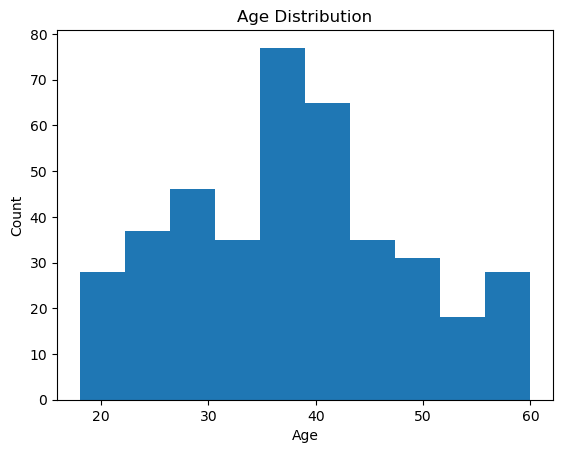

In [13]:
# 1. Age distribution 


plt.hist(df["Age"], bins=10)

plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age Distribution")

plt.show()

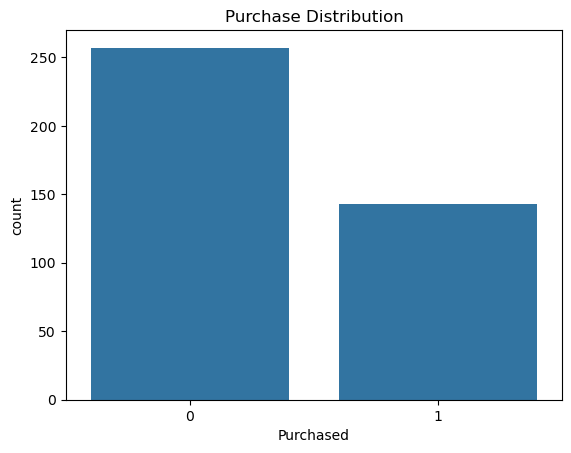

In [20]:
# 2.Purches Count 

sns.countplot(x="Purchased", data=df)

plt.title("Purchase Distribution")
plt.show()

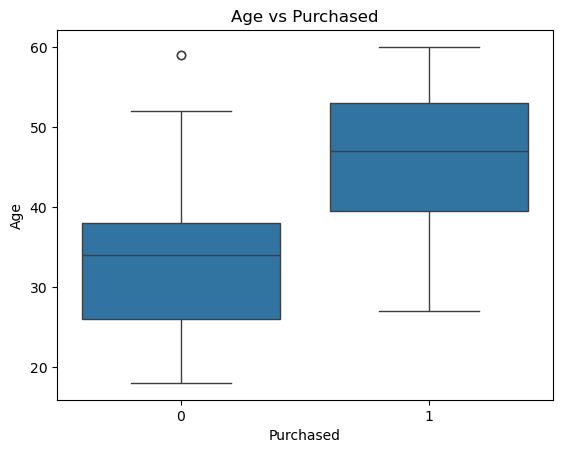

In [21]:
# Age VS Purches 

sns.boxplot(x="Purchased", y="Age", data=df)

plt.title("Age vs Purchased")
plt.show()

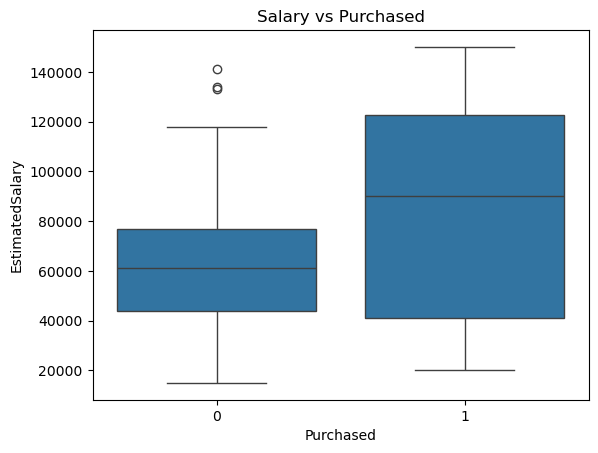

In [22]:
# 4.Salary VS Purchesed 

sns.boxplot(x="Purchased", y="EstimatedSalary", data=df)

plt.title("Salary vs Purchased")
plt.show()

In [23]:
# Converting Categorial Data into Numarical Data 

le = LabelEncoder()

df["Gender"] = le.fit_transform(df["Gender"])

df.head()

,Gender,Age,EstimatedSalary,Purchased
0,1,19,19000,0
1,1,35,20000,0
2,0,26,43000,0
3,0,27,57000,0
4,1,19,76000,0


In [28]:
# Seprate Input and output Features 

X = df.drop("Purchased", axis=1)

y = df["Purchased"]

In [29]:
# Split Training and Testing Data 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [30]:
# Feature Scaling 

sc = StandardScaler()

X_train = sc.fit_transform(X_train)

X_test = sc.transform(X_test)

In [31]:
# Model:-1   Training machine learning model 

lr = LogisticRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.8875


In [32]:
# Model:- 2  Desioon Tree Classifier 

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 0.85


In [33]:
# Model:- 3 Rnadom Forest Classifier 

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.8875


In [34]:
# Compair The Model Accuracy 

print("Logistic Regression:",
      accuracy_score(y_test, y_pred_lr))

print("Decision Tree:",
      accuracy_score(y_test, y_pred_dt))

print("Random Forest:",
      accuracy_score(y_test, y_pred_rf))

Logistic Regression: 0.8875
Decision Tree: 0.85
Random Forest: 0.8875


In [35]:
# Evaluate The Best Model 

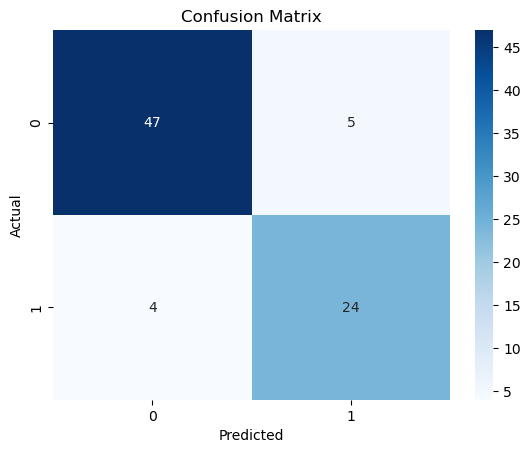

In [36]:
# Confusion matrix 

cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [37]:
# 2. classifier Report 

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.92      0.90      0.91        52
           1       0.83      0.86      0.84        28

    accuracy                           0.89        80
   macro avg       0.87      0.88      0.88        80
weighted avg       0.89      0.89      0.89        80



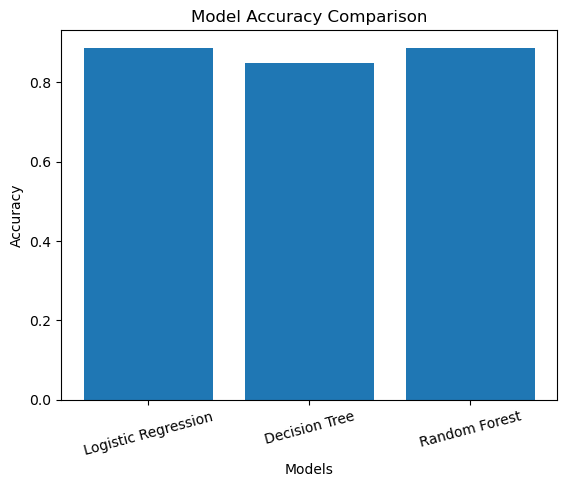

In [38]:
# Visiualize the Model Comparision 

models = ["Logistic Regression",
          "Decision Tree",
          "Random Forest"]

accuracies = [
    accuracy_score(y_test, y_pred_lr),
    accuracy_score(y_test, y_pred_dt),
    accuracy_score(y_test, y_pred_rf)
]

plt.bar(models, accuracies)

plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.xticks(rotation=15)
plt.show()

In [39]:
# make a prediction for a new coustomer 

new_customer = pd.DataFrame({
    "Gender": [1],
    "Age": [35],
    "EstimatedSalary": [60000]
})

new_customer_scaled = sc.transform(new_customer)

prediction = rf.predict(new_customer_scaled)

if prediction[0] == 1:
    print("Customer will purchase the product")
else:
    print("Customer will not purchase the product")

Customer will not purchase the product


In [41]:
# Cross-validation and GridSearchCV

from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [None, 3, 5, 10],
    "min_samples_split": [2, 5, 10]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)

print("Best CV Score:", grid.best_score_)

Best Parameters: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 50}
Best CV Score: 0.9125


In [ ]:
# Customer Purchase Prediction Using Machine Learning

# Technologies: Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

# Developed a machine learning classification model to predict customer purchase behavior using the Social Network Ads dataset.

# Performed data cleaning, exploratory data analysis (EDA), and data visualization to understand customer purchasing patterns.

# Applied feature encoding, feature scaling, and train-test splitting to prepare the dataset.

# Implemented Logistic Regression, Decision Tree, and Random Forest classification algorithms.

# Evaluated model performance using Accuracy, Confusion Matrix, Precision, Recall, and F1-score.

# Applied GridSearchCV with 5-fold cross-validation for hyperparameter tuning and model optimization.